# EDA: labelled training rows (Person D)

Goal for 10:30–11:15: compare suspicious and legitimate transactions by **leg count**, **USD value** and **cross-currency**, then check the GPU and PyG for C.

Each section ends with a short note to pass on to A, B or C.

## 0. Setup (Colab)
Upload `decode-and-detect-training-data.zip` to the Colab file pane, or put it in Drive and change `ZIP` below.

In [1]:
# from google.colab import drive; drive.mount('/content/drive')   # if the zip is in Drive
import os, zipfile
ZIP = '/content/decode-and-detect-training-data.zip'   # or '/content/drive/MyDrive/...'
ROOT = '/content/data'
if not os.path.exists(ROOT):
    zipfile.ZipFile(ZIP).extractall(ROOT)
for dirpath, _, files in os.walk(ROOT):
    if 'labels.csv' in files:
        TRAIN = dirpath
DATA = os.path.dirname(TRAIN)          # folder holding train/, validation/, payments.py
print(TRAIN)

/content/data/train


### GPU and PyG check (for C)

In [2]:
import torch
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
try:
    import torch_geometric
except ImportError:
    !pip -q install torch_geometric
    import torch_geometric
print('PyG', torch_geometric.__version__)

torch 2.11.0+cu130 | CUDA: True NVIDIA RTX PRO 6000 Blackwell Server Edition
PyG 2.8.1


## 1. Load and join

In [3]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, DATA)
from payments import load_rates, price, XRP

tx  = pd.read_parquet(f'{TRAIN}/transactions.parquet')
tr  = pd.read_parquet(f'{TRAIN}/transfers.parquet')
lab = pd.read_csv(f'{TRAIN}/labels.csv')
rates = load_rates(TRAIN)
for name, df in [('transactions', tx), ('transfers', tr), ('labels', lab)]:
    print(f'{name:13s} {df.shape}')
assert tx.TRANSACTION_HASH.is_unique and set(tx.TRANSACTION_HASH) == set(lab.TRANSACTION_HASH)

transactions  (40131, 26)
transfers     (60557, 16)
labels        (40131, 6)


**Value every leg in USD.** An asset is `(TOKEN_ADDRESS, SYMBOL)`: USD from one issuer is a different asset from USD from the other. `market_rates.csv` uses `XRP` or `issuer:currency`, priced for the hour containing the timestamp.

In [4]:
tr['TS'] = tr.TIMESTAMP.astype(int)
tr['ASSET'] = np.where(tr.TOKEN_ADDRESS == XRP, 'XRP', tr.TOKEN_ADDRESS + ':' + tr.SYMBOL)
tr['USD'] = [v * price(rates, t, a) / 1e6 for v, t, a in zip(tr.VALUE, tr.TS, tr.ASSET)]

tx['TS'] = tx.TIMESTAMP.astype(int)
extra = tx.EXTRA_TRANSACTION_FIELDS.map(json.loads)
tx['DEST'] = extra.map(lambda f: f['Destination'])
tx['HAS_SENDMAX'] = extra.map(lambda f: 'SendMax' in f)
tx['HAS_PATHS'] = extra.map(lambda f: 'Paths' in f)

legs = tr.groupby('TRANSACTION_HASH').agg(
    n_legs=('TRANSFER_INDEX', 'size'),
    n_assets=('ASSET', 'nunique'),
    n_symbols=('SYMBOL', 'nunique'),
    usd_max=('USD', 'max'),
    usd_first=('USD', 'first'),      # first executed leg = actual source cost
    usd_last=('USD', 'last'),        # last leg = what the destination received
)
legs['cross_currency'] = legs.n_assets > 1
legs['slippage'] = 1 - legs.usd_last / legs.usd_first

df = (tx[['TRANSACTION_HASH', 'TS', 'DATETIME', 'ACCOUNT', 'DEST', 'HAS_SENDMAX', 'HAS_PATHS']]
      .merge(legs, left_on='TRANSACTION_HASH', right_index=True)
      .merge(lab, on='TRANSACTION_HASH'))
df.head()

,TRANSACTION_HASH,TS,DATETIME,ACCOUNT,DEST,HAS_SENDMAX,HAS_PATHS,n_legs,n_assets,n_symbols,usd_max,usd_first,usd_last,cross_currency,slippage,is_suspicious,family,difficulty,scenario_id,cohort_id
0,954736A6E1BB5A3433EB916D8221F2DF5938A521EA2222...,1788718916,2026-09-06 18:21:56+00:00,r3CWFt1SXiykW92LwKU19CvfTFcFRnbnDY,rMWFzNYApzeKVcHyXGSUz2XQpuHmSA11kU,False,False,1,1,1,762.498271,762.498271,762.498271,False,0.000000,0,distributed_relay,normal,FE69BD6006442F8EC89DF22D,E81F51237BFB886CCD49C77A
1,C93CF387C2148608329ED89420105EFD883020CDBFDFAE...,1788766300,2026-09-07 07:31:40+00:00,rEFG2WG1W8bHQhHp2P1rcxRBMxmz9C52B7,rDwLP5NUvC25gwBDHgv5qP9nCZjT8kuZSy,False,False,1,1,1,317.038538,317.038538,317.038538,False,0.000000,0,distributed_relay,normal,6E8A810AB5736B41F90EA3E0,2D24F4A6479987DCBE8FAE97
2,E46BFC5EC409B486E1C97F20BCB62AE96432B20937D265...,1788737068,2026-09-06 23:24:28+00:00,rJxqpGRZ2bJtB1Q8HYCV9iPon9HpvJugZm,rsSAFra1UVoobuNrQzh7HJHepjvSTkHyAM,False,False,1,1,1,1.885882,1.885882,1.885882,False,0.000000,0,background,normal,NaN,NaN
3,E7CAB61BBDAC502147EF393C7EA93A2A937DA3F01623E2...,1788574820,2026-09-05 02:20:20+00:00,rnEiuUDCbbsMqipLBQvUvkQyjhcM1vDtHB,rP5qUwE6qmTDzME7kqjP4CGAb8v9x17QE6,True,True,3,3,3,12.497875,12.425732,12.497875,True,-0.005806,0,background,normal,NaN,NaN
4,E9549020D2717DB401CA4C30BB82500758ABF100600D9C...,1788707968,2026-09-06 15:19:28+00:00,rwWTLZeD4QEMAiJ4QsmVgeWDJj6NMrw4Bx,rGkwo8Zrgj3hMT61iswFgnxGTs3ALKEgCU,True,False,2,2,2,106.400625,106.400625,106.358082,True,0.000400,0,background,normal,NaN,NaN


## 2. Labels: what we are predicting

In [5]:
print(df.is_suspicious.value_counts(), f"\npositive rate {df.is_suspicious.mean():.2%}")
print(pd.crosstab(df.family, [df.difficulty]).assign(total=lambda x: x.sum(1)).sort_values('total', ascending=False))

is_suspicious
0    38881
1     1250
Name: count, dtype: int64 
positive rate 3.11%
difficulty         easy  hard  medium  normal  total
family                                              
background            0     0       0   18000  18000
aggregate_relay       0   102       0   10098  10200
distributed_relay     0    98       0    9702   9800
multi_stage         131     0      42     165    338
fan_out_in          156     0      22     152    330
bipartite           113     0      21     152    286
random               58     0      22     178    258
stack                64     0      52     104    220
cycle                66     0      12     113    191
fan_in               83     0      18      76    177
fan_out              66     0      26      75    167
chain                63     0      10      66    139
ambiguous             0    25       0       0     25


Things to note here:

- About **3.1% positive** (1,250 of 40,131). A random ranking gets AP ≈ 0.031, so treat that as the floor.
- `family` is **not** the same as the label. Most families have both suspicious rows and legitimate look-alikes (`aggregate_relay` has 102 positives among ~10k rows). The model has to separate a pattern from its decoy.
- `family`, `difficulty`, `scenario_id` and `cohort_id` are **annotation only** and don't exist in test. Never use them as features. They're fine for grouping CV folds and for error analysis.
- The 25 `ambiguous` positives are random by design, so no model will catch them.

## 3. Suspicious vs legit by leg count

In [6]:
def rate_table(col):
    t = df.groupby(col).is_suspicious.agg(n='size', suspicious='sum', rate='mean')
    t['lift'] = t.rate / df.is_suspicious.mean()
    return t.round(3)
rate_table('n_legs')

,n,suspicious,rate,lift
n_legs,,,,
1,23681,733,0.031,0.994
2,12474,399,0.032,1.027
3,3976,118,0.030,0.953


In [7]:
pd.crosstab(df.n_legs, df.difficulty, normalize='columns').round(3)

difficulty,easy,hard,medium,normal
n_legs,,,,
1,0.568,0.618,0.622,0.590
2,0.340,0.284,0.280,0.311
3,0.092,0.098,0.098,0.099


## 4. Suspicious vs legit by USD value

/tmp/ipykernel_1593/3835814024.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(col).is_suspicious.agg(n='size', suspicious='sum', rate='mean')


,count,mean,std,min,10%,50%,90%,max
difficulty,,,,,,,,
easy,800.0,167.2,242.4,1.0,18.0,84.6,416.2,2112.9
hard,225.0,246.1,350.6,3.7,23.2,124.6,585.9,2356.0
medium,225.0,134.7,184.1,7.2,18.4,68.3,341.1,1204.0
normal,38881.0,140.5,232.0,0.5,10.3,58.5,357.5,4575.7


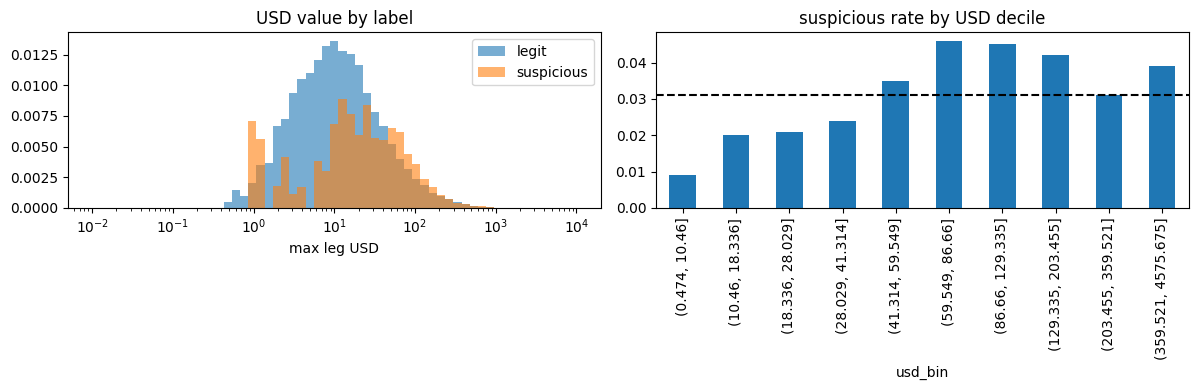

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(-2, 4, 60)
for y, name in [(0, 'legit'), (1, 'suspicious')]:
    axes[0].hist(df.loc[df.is_suspicious == y, 'usd_max'], bins=bins, density=True, alpha=.6, label=name)
axes[0].set_xscale('log'); axes[0].set_xlabel('max leg USD'); axes[0].legend(); axes[0].set_title('USD value by label')
df['usd_bin'] = pd.qcut(df.usd_max, 10)
rate_table('usd_bin').rate.plot.bar(ax=axes[1], title='suspicious rate by USD decile')
axes[1].axhline(df.is_suspicious.mean(), ls='--', c='k'); plt.tight_layout()
df.groupby('difficulty').usd_max.describe(percentiles=[.1, .5, .9]).round(1)

In [9]:
# round amounts in the delivered asset's units (last leg)
last = df.TRANSACTION_HASH.map(tr.sort_values('TRANSFER_INDEX').groupby('TRANSACTION_HASH').VALUE.last()).round(6)
for step in [100, 10, 1, 0.01]:
    print(f'multiple of {step:>6}: {(last % step).round(6).eq(0).sum()} txs')
# expect ~0 everywhere: amounts carry 6 noisy decimals -> tell B to drop 'round amounts'

multiple of    100: 0 txs
multiple of     10: 0 txs
multiple of      1: 0 txs
multiple of   0.01: 2 txs


## 5. Cross-currency

In [10]:
display(rate_table('cross_currency'))
display(rate_table('n_assets'))
display(df.groupby('is_suspicious').slippage.describe().round(4))

,n,suspicious,rate,lift
cross_currency,,,,
False,23681,733,0.031,0.994
True,16450,517,0.031,1.009


,n,suspicious,rate,lift
n_assets,,,,
1,23681,733,0.031,0.994
2,12474,399,0.032,1.027
3,3976,118,0.030,0.953


,count,mean,std,min,25%,50%,75%,max
is_suspicious,,,,,,,,
0,38881.0,0.0000,0.0025,-0.012,0.0,0.0,0.0,0.0118
1,1250.0,0.0001,0.0024,-0.011,0.0,0.0,0.0,0.0095


In [11]:
# which asset pairs (first leg -> last leg)
ends = tr.sort_values('TRANSFER_INDEX').groupby('TRANSACTION_HASH').ASSET.agg(['first', 'last'])
short = lambda a: a if a == 'XRP' else a.split(':')[0][:5] + ':' + a.split(':')[1]
df['pair'] = df.TRANSACTION_HASH.map(ends['first'].map(short) + ' -> ' + ends['last'].map(short))
rate_table('pair').sort_values('n', ascending=False)

,n,suspicious,rate,lift
pair,,,,
XRP -> XRP,9668,317,0.033,1.053
r99vy:GBP -> r99vy:GBP,4611,116,0.025,0.808
rLeMq:EUR -> rLeMq:EUR,3233,118,0.036,1.172
rLeMq:USD -> rLeMq:USD,3178,101,0.032,1.020
r99vy:USD -> r99vy:USD,2991,81,0.027,0.869
rLeMq:EUR -> r99vy:GBP,895,35,0.039,1.255
r99vy:USD -> XRP,890,21,0.024,0.758
rLeMq:USD -> r99vy:USD,879,16,0.018,0.584
r99vy:USD -> r99vy:GBP,879,25,0.028,0.913


### Checkpoint: what sections 3–5 say

On this data, **leg count, cross-currency, asset pair and round amounts barely move the suspicious rate** (everything sits around 3%, lift ≈ 1). The README said as much: *"look at aggregate flows and context, not just isolated payment amounts or fixed routes."* USD value shifts a little (suspicious rows run a bit larger), so it's a weak feature.

**Tell the team:** per-transaction leg features alone will give a weak GBDT. The signal is in **accounts, time and graph structure**, which backs up C's GNN plan and B's account aggregates. The next sections show where that signal is.

## 6. Where the signal is: accounts and scenarios

accounts total       700
suspicious senders   443 | receivers 464
txs per scenario     {'count': 169.0, 'mean': 7.4, 'std': 4.7, 'min': 1.0, '25%': 5.0, '50%': 7.0, '75%': 10.0, 'max': 28.0}
0.6553254437869822 of senders have >=1 suspicious tx


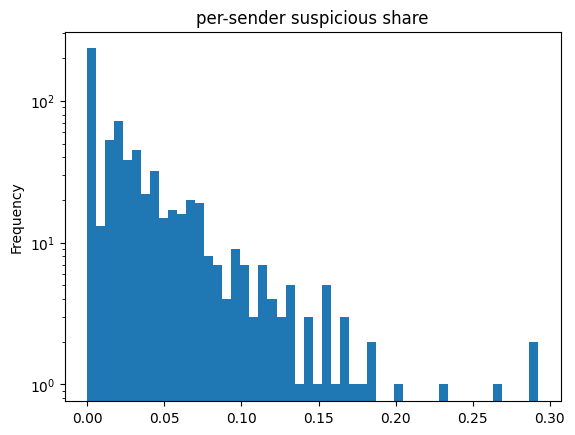

In [12]:
s = df[df.is_suspicious == 1]
print('accounts total      ', pd.unique(df[['ACCOUNT', 'DEST']].values.ravel()).size)
print('suspicious senders  ', s.ACCOUNT.nunique(), '| receivers', s.DEST.nunique())
print('txs per scenario    ', s.groupby('scenario_id').size().describe().round(1).to_dict())

# per-account share of sent txs that are suspicious
acc = df.groupby('ACCOUNT').is_suspicious.agg(['size', 'mean'])
print((acc['mean'] > 0).mean(), 'of senders have >=1 suspicious tx')
acc['mean'].plot.hist(bins=50, logy=True, title='per-sender suspicious share');

If most senders were either all-legit or mostly-suspicious, account identity alone would carry the label. Here it doesn't: only ~700 accounts, each with ~40–300 txs, and about two-thirds of senders have at least one suspicious tx. Suspicious txs come from busy accounts that are mostly legitimate, so **labels live on transactions, not accounts**. That supports C's tx-node bipartite design over account-node classification. Degree is also similar for both classes (suspicious slightly lower).

In [13]:
# degree of the accounts involved: are suspicious txs between low-activity or hub accounts?
deg = pd.concat([df.ACCOUNT, df.DEST]).value_counts()
df['src_deg'] = df.ACCOUNT.map(deg); df['dst_deg'] = df.DEST.map(deg)
df.groupby('is_suspicious')[['src_deg', 'dst_deg']].describe(percentiles=[.1, .5, .9]).T.round(0)

is_suspicious        0       1
src_deg count  38881.0  1250.0
        mean     125.0   114.0
        std       46.0    32.0
        min       43.0    44.0
        10%       78.0    76.0
        50%      117.0   112.0
        90%      170.0   153.0
        max      314.0   314.0
dst_deg count  38881.0  1250.0
        mean     132.0   114.0
        std       45.0    32.0
        min       43.0    43.0
        10%       82.0    73.0
        50%      124.0   112.0
        90%      190.0   154.0
        max      314.0   242.0

## 7. Time: pass-through and bursts

In [14]:
# pass-through: receiver sends money on within 1h of receiving it
df = df.sort_values('TS').reset_index(drop=True)
out_ts = df.groupby('ACCOUNT').TS.apply(np.sort)
def forwards_within(dest, ts, window=3600):
    t = out_ts.get(dest)
    if t is None: return False
    i = np.searchsorted(t, ts, side='right')
    return i < len(t) and t[i] - ts <= window
df['dest_forwards_1h'] = [forwards_within(d, t) for d, t in zip(df.DEST, df.TS)]
rate_table('dest_forwards_1h')

,n,suspicious,rate,lift
dest_forwards_1h,,,,
False,26845,613,0.023,0.733
True,13286,637,0.048,1.539


In [15]:
# sender burstiness: txs from the same sender in the surrounding 10 minutes
df['sender_10m'] = df.groupby('ACCOUNT').TS.transform(
    lambda t: np.searchsorted(t.values, t.values + 300, 'right') - np.searchsorted(t.values, t.values - 300, 'left'))
df['sender_10m_bin'] = pd.cut(df.sender_10m, [0, 1, 2, 5, 10, 1e9])
rate_table('sender_10m_bin')

/tmp/ipykernel_1593/3835814024.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(col).is_suspicious.agg(n='size', suspicious='sum', rate='mean')


,n,suspicious,rate,lift
sender_10m_bin,,,,
"(0.0, 1.0]",33240,771,0.023,0.745
"(1.0, 2.0]",5205,165,0.032,1.018
"(2.0, 5.0]",1606,242,0.151,4.838
"(5.0, 10.0]",80,72,0.900,28.894
"(10.0, 1000000000.0]",0,0,NaN,NaN


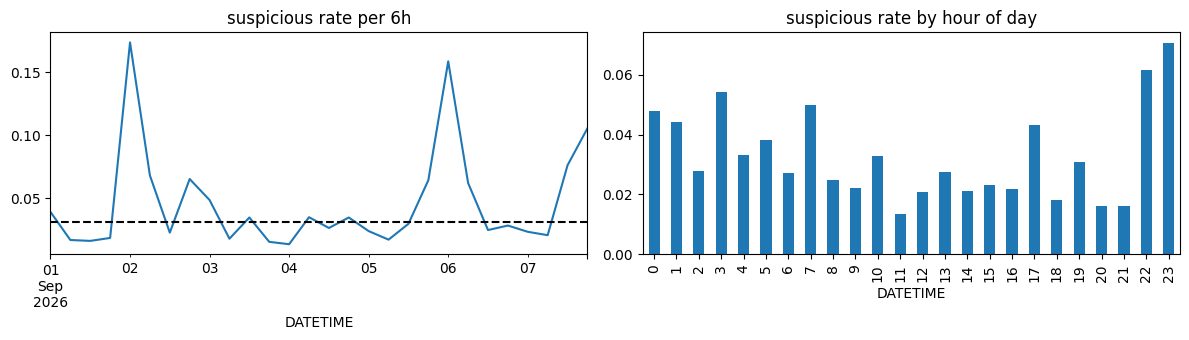

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
daily = df.set_index('DATETIME').resample('6h').is_suspicious.agg(['size', 'mean'])
daily['mean'].plot(ax=ax[0], title='suspicious rate per 6h'); ax[0].axhline(df.is_suspicious.mean(), ls='--', c='k')
df.groupby(df.DATETIME.dt.hour).is_suspicious.mean().plot.bar(ax=ax[1], title='suspicious rate by hour of day'); plt.tight_layout()

Expect **sender bursts** to be the strongest single signal: a sender with 6–10 txs in a 10-minute window is ~90% suspicious, and 3–5 txs is ~15% (5× lift). Pass-through within 1h gives ~1.5× lift. These are temporal-neighbourhood features, so the GNN needs time information on its edges or nodes.

**For C and A (split rule):** the positive rate is **not flat over the week**. Day 2 runs about twice the average. A time-based split has to put enough positives in validation, so check the counts:

In [17]:
cut = df.TS.quantile(0.8)
for name, part in [('train (first 80% of time)', df[df.TS <= cut]), ('val (last 20%)', df[df.TS > cut])]:
    print(f'{name:28s} n={len(part):6d}  pos={part.is_suspicious.sum():4d}  rate={part.is_suspicious.mean():.3%}')
# scenarios that straddle the cut leak context across the split
sc = df[df.is_suspicious == 1].groupby('scenario_id').TS.agg(['min', 'max'])
print('scenarios crossing the cut:', ((sc['min'] <= cut) & (sc['max'] > cut)).sum(), 'of', len(sc))

train (first 80% of time)    n= 32105  pos= 993  rate=3.093%
val (last 20%)               n=  8026  pos= 257  rate=3.202%
scenarios crossing the cut: 12 of 169


## 8. Quick feature-ranking check

In [18]:
from sklearn.metrics import average_precision_score as ap
feats = ['n_legs', 'n_assets', 'usd_max', 'slippage', 'HAS_PATHS',
         'src_deg', 'dst_deg', 'dest_forwards_1h', 'sender_10m']
out = {f: ap(df.is_suspicious, df[f].astype(float).fillna(0)) for f in feats}
out |= {f + ' (neg)': ap(df.is_suspicious, -df[f].astype(float).fillna(0)) for f in feats}
pd.Series(out).sort_values(ascending=False).to_frame('AP (baseline ≈ 0.031)').round(4)

,AP (baseline ≈ 0.031)
sender_10m,0.1433
dst_deg (neg),0.0433
dest_forwards_1h,0.0397
usd_max,0.0386
src_deg (neg),0.0362
slippage,0.0319
HAS_PATHS (neg),0.0313
n_legs,0.0311
n_assets,0.0311
n_legs (neg),0.0311


Single-feature AP tells you which raw signals beat random (0.031) before any model sees them. Send the top ones to B and A.

## 9. Summary to post in the team chat

Filled in from the Colab run above.

- **Labels:** 3.11% suspicious (1,250 of 40,131), so random ranking gives AP ≈ 0.031. `family`/`difficulty`/`scenario_id`/`cohort_id` are annotation only, never features (fine for CV grouping and error analysis). Every family except `background` and `ambiguous` mixes suspicious rows with legitimate look-alikes.
- **Leg count / cross-currency / asset pair / slippage:** lift 0.95–1.03 for leg count and asset count, single-feature AP ≈ 0.031 → no signal on their own.
- **Round amounts:** none exist (0 txs are a multiple of 1 unit, 2 of 0.01) → B should drop this feature.
- **USD:** median easy $84.6 / medium $68.3 / hard $124.6 vs legit $58.5; single-feature AP 0.039 → weak.
- **Strongest raw signals:**
  - Sender burst (txs from the same sender within ±5 min): 6–10 → 90% suspicious (lift 28.9), 3–5 → 15% (lift 4.8); single-feature AP **0.143**.
  - Pass-through (receiver sends on within 1h): 4.8% vs 2.3% suspicious (lift 1.54); AP 0.040.
  - Lower receiver degree: AP 0.043. Both classes sit at a median of ~112–124 txs per account.
  - These are temporal-neighbourhood signals, so the GNN needs time on its edges/nodes.
- **Graph design:** 700 accounts; 66% of senders have ≥1 suspicious tx (443 suspicious senders, 464 receivers). Labels live on transactions, not accounts → supports C's tx-node classification.
- **Scenarios:** 169 suspicious scenarios, median 7 txs each (max 28).
- **Time split:** last 20% of time → val n=8,026, 257 positives (3.20%) vs train 993 (3.09%); 12 of 169 scenarios cross the cut. Consider grouping folds by `scenario_id`, and don't split by whole day (the positive rate varies across the week).
- **Compute:** GPU OK (this run: NVIDIA RTX PRO 6000 Blackwell; an earlier runtime gave a Tesla T4, so the assigned GPU varies). torch 2.11.0+cu130, PyG 2.8.1 (installed by the notebook on each new runtime).